# Certified image reconstruction

Periodic isotropic TV supplies a useful bridge between convex duality, first-order algorithms and a real image task. A stopping certificate does not establish that smoothing improved the unknown image.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT=Path.cwd()
if ROOT.name == "notebooks": ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
def read(name): return json.loads((ROOT/name).read_text())


## Verify the adjoint

In [2]:
from optimization_lab.primal_dual import gradient, adjoint, denoise
rng=np.random.default_rng(12)
x=rng.normal(size=(8,7)); p=rng.normal(size=(2,8,7))
assert abs(np.sum(gradient(x)*p)-np.sum(x*adjoint(p))) < 1e-12
print("Periodic adjoint identity verified")

Periodic adjoint identity verified


## Independent cone oracle

In [3]:
from optimization_lab.primal_dual_study import conic_reference
b=rng.normal(size=(8,7))
oracle, reference=conic_reference(b,.18)
rows=[]
for method in ["pdhg","accelerated_pdhg","dual_fista","admm"]:
    result=denoise(b,.18,method,steps=12000,gap_per_pixel=2e-9)
    assert result["certificate"]["gap"] >= -1e-10
    assert abs(result["certificate"]["primal"]-oracle["objective"]) < 1e-6
    rows.append(dict(method=method,iterations=result["iterations"],gap=result["certificate"]["gap"]))
pd.DataFrame(rows)

,method,iterations,gap
0,pdhg,40,9.161383e-11
1,accelerated_pdhg,11320,1.117680e-07
2,dual_fista,40,2.244828e-08
3,admm,60,4.613035e-09


## All measured solves

In [4]:
frame=pd.read_csv(ROOT/"docs/primal_dual_fits.csv")
assert len(frame)==72
frame.groupby(["dataset","penalty","method"])[["psnr","iterations","gap_per_pixel"]].mean()

psnr   iterations  gap_per_pixel
dataset    penalty method                                                 
photograph 0.02    accelerated_pdhg  22.592120    60.000000   8.768055e-07
                   admm              22.639740    20.000000   6.171016e-07
                   dual_fista        22.694490    20.000000   1.151375e-07
                   pdhg              22.688357    20.000000   8.791907e-08
           0.06    accelerated_pdhg  25.772146   106.666667   8.928478e-07
                   admm              25.790238    40.000000   7.604820e-07
                   dual_fista        25.789766    80.000000   4.898820e-07
                   pdhg              25.790482    86.666667   8.444597e-07
           0.15    accelerated_pdhg  23.828064   173.333333   8.525667e-07
                   admm              23.774319   286.666667   9.380194e-07
                   dual_fista        23.773733   246.666667   9.031680e-07
                   pdhg              23.774316   753.333333   9.843107e-07
piecewise  0.02    accelerated_pdhg  23.107248    60.000000   9.465296e-07
                   admm              23.176336    20.000000   6.771349e-07
                   dual_fista        23.249627    20.000000   1.644056e-07
                   pdhg              23.240782    20.000000   1.291247e-07
           0.06    accelerated_pdhg  30.774235   120.000000   7.644178e-07
                   admm              31.032453    60.000000   7.605680e-07
                   dual_fista        31.033263    80.000000   8.837090e-07
                   pdhg              31.031883   133.333333   8.554999e-07
           0.15    accelerated_pdhg  35.416576   300.000000   9.546389e-07
                   admm              35.447562   953.333333   9.956221e-07
                   dual_fista        35.451605   400.000000   9.312074e-07
                   pdhg              35.447599  2646.666667   9.964735e-07

## Real-photo convergence

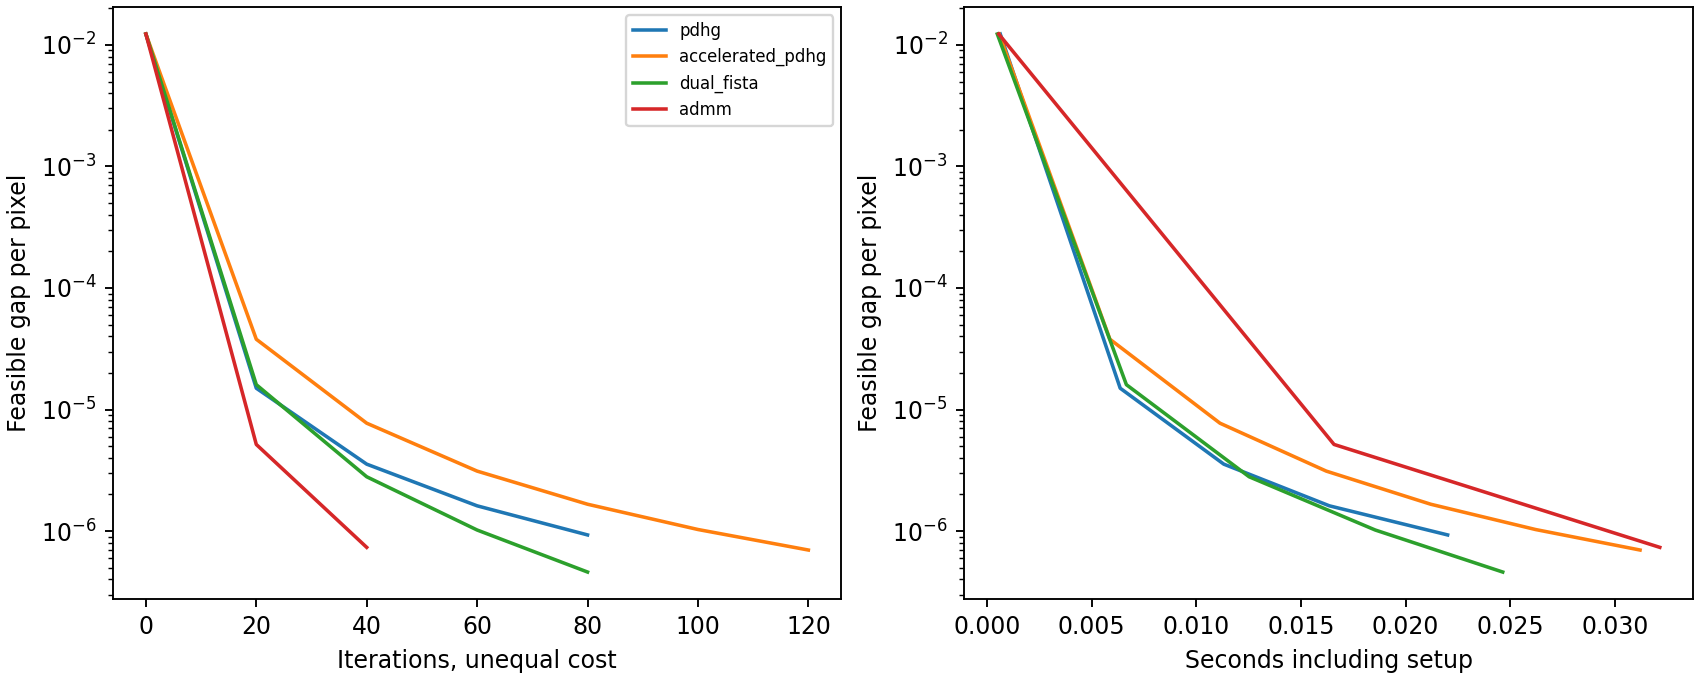

In [5]:
display(Image(filename=str(ROOT/"assets/figures/primal_dual_photograph.png")))

## Exercise and worked interpretation

Change the modeling or budget assumption and identify which claim survives. A feasible TV dual remains a lower bound for its stated objective; it does not guarantee improved PSNR. A validation winner remains the winner of its declared candidates; a larger search can still overfit selection. A route certificate uses the exact integer metric, while a visual map is only a display. Keep these claims separate when interpreting the result.